# Yellow rust yield loss in Egyptian wheat cultivars (Sharkiya), torchcrop crop

The same trial and the same FraNchEstYN disease workflow as
`sharkiya_yellow_rust_yield_loss.ipynb`, with one change: the attainable
(disease-free) crop comes from **torchcrop's Lintul5** model instead of
FraNchEstYN's internal crop model. The data are those of Omara et al. (2016,
Egypt. J. Phytopathol. 44(1):191–203): seven bread-wheat cultivars at
Sharkiya in 2013/14 and 2014/15, each grown protected by fungicide and
infected, with weekly stripe-rust severity and the grain yield of both
treatments. The measured loss is `(1 − Y_infected / Y_protected) × 100`.

**Workflow.**

1. **torchcrop**: potential production of every cultivar and season.
   Phenology is set to a mid-May maturity; the yield level is fitted per
   cultivar to its two protected-plot yields. This replaces the vignette's
   crop step and the radiation-use-efficiency part of its cultivar step.
2. **FraNchEstYN, disease** (vignette step 2): the yellow-rust parameters are
   calibrated on Sids-12, driven by the torchcrop run of Sids-12.
3. **FraNchEstYN, cultivars** (vignette step 3): only the varietal resistance
   is fitted per cultivar.

The last section compares simulated and measured loss.

## Assumptions specific to the torchcrop crop

- **Potential production.** No water or nitrogen stress (`IOPT=1`, automatic
  irrigation). Sharkiya lies in the irrigated Nile Delta, rain is negligible
  in both seasons (printed below), and the paper says the trial "received the
  agricultural practices recommended for the wheat crop". Irrigation and
  fertiliser amounts are not reported, so they are not simulated.
- **One crop parameter set for all cultivars** (torchcrop's `wheat` preset,
  a spring-type wheat with no vernalisation or day-length response), except
  the yield level (`scale_factor_rue`), which is fitted per cultivar.
- **Phenology is not observed.** The paper gives neither sowing nor
  flowering nor maturity dates. Sowing is DOY 300 and maturity is put on
  DOY 135 (15 May), the date of the yield observations, as in notebook 1.
  Grain filling keeps the preset's thermal time (`TSUM2` = 1000 °C d);
  `TSUM1` takes the rest.
- **Weather.** The same NASA POWER grid cell and days as notebook 1. torchcrop
  also uses its radiation (CERES), wind and dew point. FraNchEstYN reads the
  same Tmax, Tmin and rain file as in notebook 1, so the disease model sees
  exactly the same weather in both notebooks.
- **Yield moisture.** Measured yields are grain at market moisture (the
  paper's ardab feddan⁻¹); torchcrop's yield is dry matter. The paper gives no
  moisture content, so no conversion is made. This sets the absolute yield
  level, not the loss.

As in notebook 1, both yields of every cultivar-season are calibration
targets, so the loss comparison is a fit, not a prediction.

In [1]:
import copy
import dataclasses
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from torchcrop import CropParameters, Lintul5Model, SiteParameters, SoilParameters, WeatherDriver

from simpest.models import franchestyn as fr
from simpest.models import fr_diagnostics as diag
from simpest.models import fr_inputs

DATA = Path("SharkiyaData")
START_YEAR, END_YEAR = 2013, 2015
SUSCEPTIBLE = "sids12"
HARVEST_DOY = 135
G_M2_TO_KG_HA = 10.0          # torchcrop biomass is g m-2
CALIB = dict(optimizer="optuna", n_trials=999, seed=1, n_jobs=5)

torch.manual_seed(0)
device = torch.device("cpu")

## 1. Observations

The same files as notebook 1.

In [2]:
disease_obs = pd.read_csv(DATA / "disease" / "disease.csv")
yield_obs = pd.read_csv(DATA / "yield" / "yield.csv")
ref_df = disease_obs.merge(yield_obs, on=["site", "variety", "year", "DOY"], how="left")
yield_obs["season"] = yield_obs["year"] - 1
yield_obs["loss_measured"] = (1 - yield_obs["yieldActual"] / yield_obs["yieldAttainable"]) * 100
VARIETIES = list(disease_obs["variety"].unique())
yield_obs.pivot(index="variety", columns="season", values=["yieldAttainable", "yieldActual", "loss_measured"]).round(0).loc[VARIETIES]

yieldAttainable         yieldActual         loss_measured      
season             2013    2014        2013    2014          2013  2014
variety                                                                
sids12           7607.0  7286.0      3393.0  3036.0          55.0  58.0
gem11            7964.0  7143.0      3714.0  3071.0          53.0  57.0
gem7             6679.0  6357.0      3821.0  3393.0          43.0  47.0
sids13           7071.0  6250.0      4893.0  4036.0          31.0  35.0
sids1            6321.0  5893.0      4107.0  3571.0          35.0  39.0
gem9             7107.0  7179.0      5393.0  5250.0          24.0  27.0
gem10            6786.0  5821.0      5500.0  4429.0          19.0  24.0

## 2. torchcrop dataset

`SharkiyaData/` holds the torchcrop inputs in the Indiana layout, one
"location" per sowing season, written by
`tools/fetch_power_torchcrop_dataset.py`:

| file | content | source |
|---|---|---|
| `weather/2013.csv`, `weather/2014.csv` | daily weather from 1 January of the sowing year, 570 days | NASA POWER daily (MERRA-2 temperature, rain, wind, dew point; CERES radiation) |
| `site/site.csv` | latitude, altitude, sowing DOY (`IDPL` = 300), CO₂ | elevation from Open-Meteo (9 m; the paper gives 71 ft); CO₂: NOAA Mauna Loa annual mean of the sowing year |
| `soil/soil.csv` | soil water parameters | SoilGrids texture (35 % clay) through Saxton–Rawls (2006), generic LINTUL5 defaults. With automatic irrigation they do not limit growth. |

The reader and collate function are those of the Indiana notebook.

In [3]:
WEATHER_COLS = ["Date", "TempMean", "TempMin", "TempMax", "Radiation", "Precipitation", "VapPressure", "Windspeed"]
SOIL_MAP = {"SMDRY": "wcad", "SMW": "wcwp", "SMFC": "wcfc", "SMO": "wcst", "CRAIRC": "crairc", "SMI": "wci",
            "SMLOWI": "wci_lower", "RDMSO": "rdmso", "RUNFR": "runfr", "CFEV": "cfev", "KSUB": "ksub",
            "NMINS": "nmini", "PMINS": "pmini", "KMINS": "kmini", "RTNMINS": "rtnmins", "RTPMINS": "rtpmins",
            "RTKMINS": "rtkmins"}
SITE_MAP = {"LATITUDE": "latitude", "ALTITUDE": "altitude", "IDPL": "idpl", "CO2": "co2"}

site_data = pd.read_csv(DATA / "site" / "site.csv").set_index("location")
soil_data = pd.read_csv(DATA / "soil" / "soil.csv").set_index("location")
SEASONS = [int(s) for s in site_data.index]          # sowing years


def load_weather(season):
    df = pd.read_csv(DATA / "weather" / f"{season}.csv", parse_dates=["Date"], dayfirst=True)[WEATHER_COLS].copy()
    df["TempMean"] = (df["TempMin"] + df["TempMax"]) / 2.0
    df["Radiation"] = df["Radiation"] / 1000.0      # kJ -> MJ m-2 d-1
    df["Date"] = df["Date"].dt.dayofyear
    return torch.as_tensor(df.values, dtype=torch.float32)


# One batch row per cultivar and season: [cv1 2013, cv1 2014, cv2 2013, ...], so
# each cultivar can have its own yield level in a single forward pass.
rows = [(v, s) for v in VARIETIES for s in SEASONS]
weather = WeatherDriver(torch.stack([load_weather(s) for _, s in rows]))
soil_params = SoilParameters(**{f: torch.tensor([float(soil_data.loc[s, c]) for _, s in rows]) for c, f in SOIL_MAP.items()})
site_params = SiteParameters(**{f: torch.tensor([float(site_data.loc[s, c]) for _, s in rows]) for c, f in SITE_MAP.items()})
soil_params.irri = torch.tensor(1.0)               # automatic irrigation: no water stress
fertilizer = torch.zeros(len(rows), weather.data.shape[1], 3)

crop_params = CropParameters(crop_name="wheat")    # spring-type preset: IDSL = 0, no vernalisation
crop_params.iopt = torch.tensor(1.0)               # potential production: no water or N stress

for s in SEASONS:
    w = pd.read_csv(DATA / "weather" / f"{s}.csv", parse_dates=["Date"], dayfirst=True)
    in_season = (w["Date"] >= pd.Timestamp(s, 1, 1) + pd.Timedelta(days=299)) & \
                (w["Date"] <= pd.Timestamp(s + 1, 1, 1) + pd.Timedelta(days=HARVEST_DOY - 1))
    print(f"{s}/{s + 1 - 2000:02d}: rain from sowing to harvest {w.loc[in_season, 'Precipitation'].sum():.0f} mm")

2013/14: rain from sowing to harvest 43 mm
2014/15: rain from sowing to harvest 56 mm


## 3. Phenology

With no observed dates, maturity is put on DOY 135. A probe run with the
TSUMs out of reach gives the thermal time from emergence to DOY 135 in each
season; the mean over the two seasons is split into the preset grain-filling
thermal time (`TSUM2` = 1000 °C d) and the rest (`TSUM1`).

In [4]:
def run_crop(params):
    with torch.no_grad():
        return Lintul5Model(params, soil_params, site_params).eval()(weather, start_doy=1, fertilizer=fertilizer)


def day_index(season, doy):
    """Index of a day of the harvest year in a season's weather, which starts on 1 January of the sowing year."""
    return (pd.Timestamp(season + 1, 1, 1) + pd.Timedelta(days=doy - 1) - pd.Timestamp(season, 1, 1)).days


probe_params = copy.deepcopy(crop_params)
probe_params.tsum1 = torch.tensor(1e4)
probe_params.tsum2 = torch.tensor(1e5)
probe = run_crop(probe_params)
tsum = torch.stack([s.tsum for s in probe.states], dim=1).numpy()       # column d + 1 = end of day d
tt_harvest = {s: float(tsum[rows.index((VARIETIES[0], s)), day_index(s, HARVEST_DOY) + 1]) for s in SEASONS}
print("Thermal time emergence -> DOY 135:", {s: round(v) for s, v in tt_harvest.items()})

TSUM2 = float(crop_params.tsum2)
TSUM1 = float(np.mean(list(tt_harvest.values()))) - TSUM2
crop_params.tsum1 = torch.tensor(TSUM1)
print(f"TSUM1 = {TSUM1:.0f} degC d (preset 1050), TSUM2 = {TSUM2:.0f} degC d (preset)")

base_run = run_crop(crop_params)
dvs = base_run.dvs.numpy()[:, 1:]
pheno = pd.DataFrame([
    {"season": s,
     "anthesis": (pd.Timestamp(s, 1, 1) + pd.Timedelta(days=int(np.argmax(dvs[b] >= 1.0)))).date(),
     "maturity": (pd.Timestamp(s, 1, 1) + pd.Timedelta(days=int(np.argmax(dvs[b] >= 2.0)))).date(),
     "potential yield (preset RUE) [kg/ha]": round(float(base_run.yield_[b]) * G_M2_TO_KG_HA)}
    for b, (v, s) in enumerate(rows) if v == VARIETIES[0]
])
pheno

Thermal time emergence -> DOY 135: {2013: 3712, 2014: 3538}
TSUM1 = 2625 degC d (preset 1050), TSUM2 = 1000 degC d (preset)


,season,anthesis,maturity,potential yield (preset RUE) [kg/ha]
0,2013,2014-03-30,2014-05-12,8337
1,2014,2015-04-03,2015-05-19,7676


## 4. Yield level per cultivar

The cultivars differ in their protected-plot yield (5,800–8,000 kg ha⁻¹).
One parameter per cultivar sets its level: `scale_factor_rue`, a multiplier
on the radiation use efficiency, bounded to 0.5–1.5. Under potential
production yield rises steadily with it. torchcrop is differentiable, so
the seven values are fitted together by L-BFGS on the mean squared error
between simulated yield at maturity and the two protected-plot yields of
each cultivar; the bounds are kept with a sigmoid transform. The two seasons
of a cultivar share one value, so the season-to-season difference comes
from the weather.

In [5]:
RUE_BOUNDS = (0.5, 1.5)
target = torch.tensor([
    float(yield_obs.query("variety == @v and season == @s")["yieldAttainable"].iloc[0]) for v, s in rows
])
latent = torch.zeros(len(VARIETIES), requires_grad=True)


def rue_scale():
    lo, hi = RUE_BOUNDS
    return lo + (hi - lo) * torch.sigmoid(latent)


fit_params = copy.deepcopy(crop_params)
model = Lintul5Model(fit_params, soil_params, site_params)
optimizer = torch.optim.LBFGS([latent], lr=1.0, max_iter=20, max_eval=25, tolerance_change=1e-3,
                              line_search_fn="strong_wolfe")
history = []


def closure():
    optimizer.zero_grad()
    fit_params.scale_factor_rue = rue_scale().repeat_interleave(len(SEASONS))   # one value per batch row
    sim = model(weather, start_doy=1, fertilizer=fertilizer).yield_ * G_M2_TO_KG_HA
    loss = torch.mean((sim - target) ** 2)
    loss.backward()
    history.append(float(loss.detach().sqrt()))
    return loss


optimizer.step(closure)
rue_fit = dict(zip(VARIETIES, rue_scale().detach().numpy().round(3)))
print(f"{len(history)} evaluations, RMSE {history[0]:.0f} -> {history[-1]:.0f} kg/ha")

fit_params.scale_factor_rue = rue_scale().detach().repeat_interleave(len(SEASONS))
crop_run = run_crop(fit_params)
potential = pd.DataFrame(rows, columns=["variety", "season"]).assign(
    scale_factor_rue=[rue_fit[v] for v, _ in rows],
    potential=crop_run.yield_.numpy() * G_M2_TO_KG_HA,
    protected=target.numpy(),
)
potential.set_index(["variety", "season"]).round({"scale_factor_rue": 3, "potential": 0, "protected": 0})

12 evaluations, RMSE 1312 -> 178 kg/ha


scale_factor_rue  potential  protected
variety season                                        
sids12  2013               0.933     7753.0     7607.0
        2014               0.933     7130.0     7286.0
gem11   2013               0.947     7873.0     7964.0
        2014               0.947     7241.0     7143.0
gem7    2013               0.822     6793.0     6679.0
        2014               0.822     6234.0     6357.0
sids13  2013               0.840     6950.0     7071.0
        2014               0.840     6380.0     6250.0
sids1   2013               0.773     6370.0     6321.0
        2014               0.773     5840.0     5893.0
gem9    2013               0.896     7432.0     7107.0
        2014               0.896     6830.0     7179.0
gem10   2013               0.797     6583.0     6786.0
        2014               0.797     6039.0     5821.0

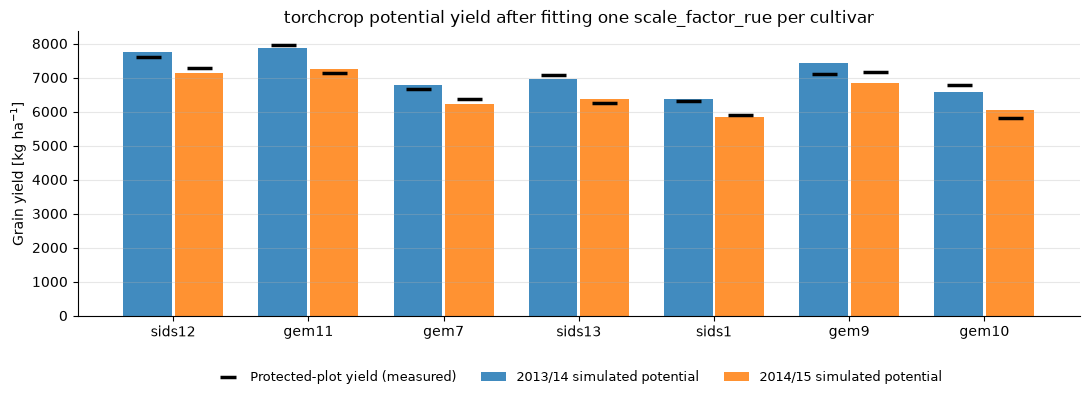

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(VARIETIES))
for k, (s, color) in enumerate(zip(SEASONS, ("#1f77b4", "#ff7f0e"))):
    d = potential[potential["season"] == s].set_index("variety").loc[VARIETIES]
    off = (k - 0.5) * 0.38
    ax.bar(x + off, d["potential"], width=0.36, color=color, alpha=0.85, label=f"{s}/{s + 1 - 2000:02d} simulated potential")
    ax.plot(x + off, d["protected"], "k_", ms=18, mew=2.5)
ax.plot([], [], "k_", ms=12, mew=2.5, label="Protected-plot yield (measured)")
ax.set_xticks(x, VARIETIES)
ax.set_ylabel("Grain yield [kg ha$^{-1}$]")
ax.set_title("torchcrop potential yield after fitting one scale_factor_rue per cultivar")
ax.grid(alpha=0.3, axis="y")
ax.legend(frameon=False, fontsize=9, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.28))
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

## 5. FraNchEstYN inputs

Each cultivar gets its own attainable crop series from its two torchcrop
rows: biomass, grain yield (storage organs), light interception and thermal
time since emergence, from sowing to maturity. Cycle completion is taken from
thermal time (`use_gdd=True`), as in the Indiana notebook. Weather is the
daily Tmax, Tmin and rain file of notebook 1. Harvest observations dated
after the simulated maturity are scored against the season's final yield
(`score_harvest_after_maturity=True`), as in notebook 1.

In [7]:
field_names = crop_run.states[0].field_names
state_traj = torch.stack([s.stack() for s in crop_run.states], dim=1).numpy()[:, 1:]   # end-of-day values
diag_names = crop_run.diagnostics[0].field_names
diag_traj = torch.stack([s.stack() for s in crop_run.diagnostics], dim=1).numpy()
dvs_traj = crop_run.dvs.numpy()[:, 1:]


def crop_model_df_for(variety):
    b = [i for i, (v, _) in enumerate(rows) if v == variety]
    st = lambda f: state_traj[b, :, field_names.index(f)]
    return fr_inputs.build_crop_model_df(
        agb=(st("wlv") + st("wlvd") + st("wst") + st("wstd") + st("wso")) * G_M2_TO_KG_HA,
        yield_=st("wso") * G_M2_TO_KG_HA,
        fint=diag_traj[b, :, diag_names.index("frac_intercepted")],
        gdd=st("tsum"),
        dvs=dvs_traj[b],
        sow_years=SEASONS,
        sowing_doys=site_data.loc[SEASONS, "IDPL"].astype(int).tolist(),
    )


weather_df = pd.read_csv(DATA / "weather" / "sharkiya_2013_2015.csv")
crop_models = {v: crop_model_df_for(v) for v in VARIETIES}
LATITUDE = float(site_data["LATITUDE"].iloc[0])


def make_config(variety, **settings):
    return fr.FranchestynConfig(
        site="Sharkiya", variety=variety, disease="disease", disease_type="yellow_rust", fungicide_type=None,
        latitude=LATITUDE, use_gdd=True, score_harvest_after_maturity=True, **settings,
    )


def run(config, variety):
    management = fr_inputs.build_management_df(site_data, site="Sharkiya", crop="wheat", variety=variety)
    return fr.run_franchestyn(START_YEAR, END_YEAR, config, weather_df, management, crop_models[variety], ref_df)


crop_models[SUSCEPTIBLE].groupby("year").size()

year
2013     66
2014    198
2015    139
dtype: int64

## 6. Step 2 — disease calibration (Sids-12)

As in notebook 1 and the vignette: `AssimilateSappersDamage`,
`RUEreducerDamage` and `SenescenceAcceleratorDamage` are set to 0 and not
calibrated, `OuterInoculumShapeRelease` is set to 1 (vignette values), and
the other flagged yellow-rust parameters, including `LightStealerDamage`,
are calibrated against the severity of Sids-12 and its infected-plot yield.
With an external crop series the crop parameters play no role, except the
varietal resistance, which stays at 0 for Sids-12.

In [8]:
dis_cfg = make_config(SUSCEPTIBLE, calibration_variable="disease", **CALIB)
fr.deactivate_calibration(dis_cfg.crop_parameters, list(dis_cfg.crop_parameters))
for name in ("AssimilateSappersDamage", "RUEreducerDamage", "SenescenceAcceleratorDamage"):
    dis_cfg.disease_parameters[name].update(value=0.0, calibration=False)   # vignette, step 2
dis_cfg.disease_parameters["OuterInoculumShapeRelease"]["value"] = 1.0       # vignette, step 2

dis_res = run(dis_cfg, SUSCEPTIBLE)
dis_best = dis_res["outputs"]["summary"]["best_params"]
fr.apply_best_params(dis_cfg, dis_best)
print("Objective (RMSE):", dis_res["outputs"]["summary"]["rmse"])
diag.bound_check(dis_best, {"disease": dis_cfg.disease_parameters}).round(3)

- Calibrating 17 using Optuna (TPE), n_trials=999.
- Parameters:
['disease_OuterInoculumMax', 'disease_PathogenSpread', 'disease_WetnessDurationOptimum', 'disease_WetnessDurationMinimum', 'disease_DryCriticalInterruption', 'disease_Tmin', 'disease_Topt', 'disease_Tmax', 'disease_RelativeHumidityCritical', 'disease_Rain50Detachment', 'disease_RelativeHumidityNotLimiting', 'disease_HydroThermalTimeOnset', 'disease_CyclePercentageOnset', 'disease_LatencyDuration', 'disease_SporulationDuration', 'disease_LightStealerDamage', 'disease_OuterInoculumShapeParameter']
- Evaluating trials in batches of 5 across 5 worker processes.


/home/rahaman/miniforge3/envs/simpest/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Trial 999/999 CURR RMSE=10.2170 BEST RMSE=9.09700
Best RMSE: 9.0970
{'disease_OuterInoculumMax': 0.09319320180315639, 'disease_PathogenSpread': 0.32107718210029634, 'disease_WetnessDurationOptimum': 19.330328212079667, 'disease_WetnessDurationMinimum': 3.552711254524317, 'disease_DryCriticalInterruption': 19.549785939953992, 'disease_Tmin': 0.7306157973092681, 'disease_Topt': 15.512285029292151, 'disease_Tmax': 24.26170273234991, 'disease_RelativeHumidityCritical': 50.17387386966834, 'disease_Rain50Detachment': 4.303615153045478, 'disease_RelativeHumidityNotLimiting': 84.65206932705348, 'disease_HydroThermalTimeOnset': 13.194300225716415, 'disease_CyclePercentageOnset': 14.414174139411442, 'disease_LatencyDuration': 9.951087049809273, 'disease_SporulationDuration': 26.41205943274814, 'disease_LightStealerDamage': 0.5215044499497425, 'disease_OuterInoculumShapeParameter': 0.7884910953075752}
Objective (RMSE): 9.097


,value,min,max,position,at_bound
parameter,,,,,
disease_OuterInoculumMax,0.093,0.01,0.14,0.640,
disease_PathogenSpread,0.321,0.01,0.50,0.635,
disease_WetnessDurationOptimum,19.330,10.00,20.00,0.933,
disease_WetnessDurationMinimum,3.553,3.00,10.00,0.079,
disease_DryCriticalInterruption,19.550,6.00,24.00,0.753,
disease_Tmin,0.731,0.00,8.00,0.091,
disease_Topt,15.512,10.00,18.00,0.689,
disease_Tmax,24.262,18.00,25.00,0.895,
disease_RelativeHumidityCritical,50.174,50.00,75.00,0.007,lower


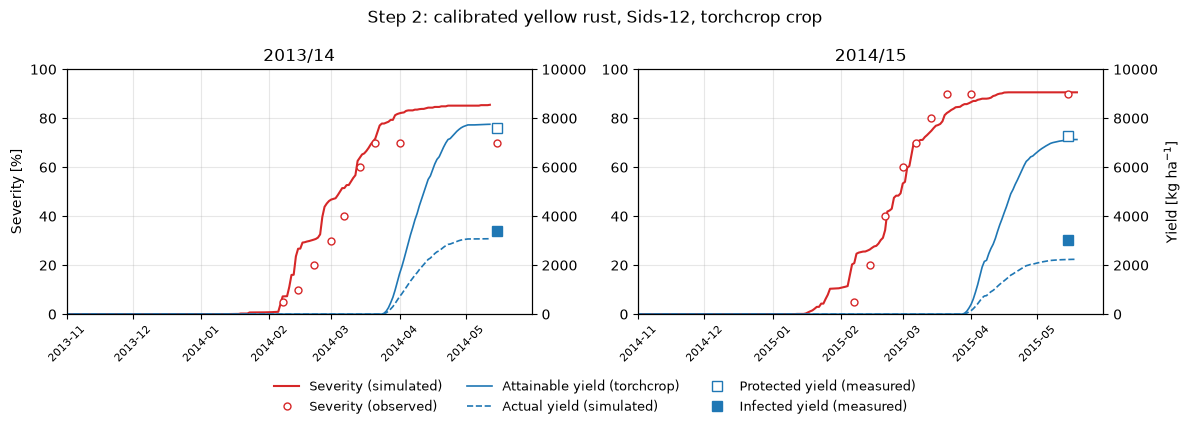

In [9]:
def obs_dates(df):
    return diag.reference_dates(df)


def plot_variety(ax, sim, variety, season):
    """Simulated vs observed severity and yields of one cultivar-season."""
    s = sim[sim["GrowingSeason"] == season]
    r = ref_df[(ref_df["variety"] == variety) & (ref_df["year"] == season + 1)]
    ax.plot(s["Date"], s["DiseaseSeverity"], color="#d62728", lw=1.5, label="Severity (simulated)")
    sev = r.dropna(subset=["disease"])
    ax.plot(obs_dates(sev), sev["disease"], "o", color="#d62728", mfc="white", ms=5, label="Severity (observed)")
    ax.set_ylim(0, 100)
    ax2 = ax.twinx()
    ax2.plot(s["Date"], s["YieldAttainable"], color="#1f77b4", lw=1.2, label="Attainable yield (torchcrop)")
    ax2.plot(s["Date"], s["YieldActual"], color="#1f77b4", lw=1.2, ls="--", label="Actual yield (simulated)")
    y = r.dropna(subset=["yieldAttainable"])
    ax2.plot(obs_dates(y), y["yieldAttainable"], "s", color="#1f77b4", mfc="white", ms=7, label="Protected yield (measured)")
    ax2.plot(obs_dates(y), y["yieldActual"], "s", color="#1f77b4", ms=7, label="Infected yield (measured)")
    ax2.set_ylim(0, 10000)
    ax.set_xlim(pd.Timestamp(season, 11, 1), pd.Timestamp(season + 1, 5, 31))
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.grid(alpha=0.3)
    return ax2


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
dis_sim = diag.simulation_frame(dis_res)
for ax, season in zip(axes, SEASONS):
    ax2 = plot_variety(ax, dis_sim, SUSCEPTIBLE, season)
    ax.set_title(f"{season}/{season + 1 - 2000:02d}")
axes[0].set_ylabel("Severity [%]")
ax2.set_ylabel("Yield [kg ha$^{-1}$]")
handles = axes[1].get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
fig.legend(handles, [h.get_label() for h in handles], loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.suptitle("Step 2: calibrated yellow rust, Sids-12, torchcrop crop")
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

## 7. Step 3 — varietal resistance per cultivar

The disease parameters of step 2 are fixed. The vignette fits two parameters
per cultivar; here the attainable yield of each cultivar already comes from
torchcrop (section 4), so only `VarietalResistance` is fitted, against the
cultivar's severity and both yields (`calibration_variable="all"`).

In [10]:
var_results = {}
for variety in VARIETIES:
    cfg = make_config(variety, calibration_variable="all", **CALIB)
    cfg.disease_parameters = copy.deepcopy(dis_cfg.disease_parameters)
    fr.deactivate_calibration(cfg.disease_parameters, list(cfg.disease_parameters))
    fr.deactivate_calibration(cfg.crop_parameters, list(cfg.crop_parameters))
    cfg.crop_parameters["VarietalResistance"]["calibration"] = True
    var_results[variety] = (cfg, run(cfg, variety))

pd.DataFrame({
    v: {"RMSE": res["outputs"]["summary"]["rmse"], "scale_factor_rue": rue_fit[v],
        **{k.split("_", 1)[1]: x for k, x in res["outputs"]["summary"]["best_params"].items()}}
    for v, (cfg, res) in var_results.items()
}).T.round(3)

- Calibrating 1 using Optuna (TPE), n_trials=999.
- Parameters:
['crop_VarietalResistance']
- Evaluating trials in batches of 5 across 5 worker processes.


Trial 999/999 CURR RMSE=10.2740 BEST RMSE=10.1240
Best RMSE: 10.1240
{'crop_VarietalResistance': 0.04610400717697722}
- Calibrating 1 using Optuna (TPE), n_trials=999.
- Parameters:
['crop_VarietalResistance']
- Evaluating trials in batches of 5 across 5 worker processes.
Trial 999/999 CURR RMSE=9.3520 BEST RMSE=9.30200
Best RMSE: 9.3020
{'crop_VarietalResistance': 0.1436842201510405}
- Calibrating 1 using Optuna (TPE), n_trials=999.
- Parameters:
['crop_VarietalResistance']
- Evaluating trials in batches of 5 across 5 worker processes.
Trial 999/999 CURR RMSE=8.0340 BEST RMSE=7.67000
Best RMSE: 7.6700
{'crop_VarietalResistance': 0.29285012970236823}
- Calibrating 1 using Optuna (TPE), n_trials=999.
- Parameters:
['crop_VarietalResistance']
- Evaluating trials in batches of 5 across 5 worker processes.
Trial 999/999 CURR RMSE=7.7870 BEST RMSE=7.78400
Best RMSE: 7.7840
{'crop_VarietalResistance': 0.5190080356020832}
- Calibrating 1 using Optuna (TPE), n_trials=999.
- Parameters:
['crop_

,RMSE,scale_factor_rue,VarietalResistance
sids12,10.124,0.933,0.046
gem11,9.302,0.947,0.144
gem7,7.670,0.822,0.293
sids13,7.784,0.840,0.519
sids1,7.398,0.773,0.429
gem9,7.901,0.896,0.629
gem10,6.448,0.797,0.778


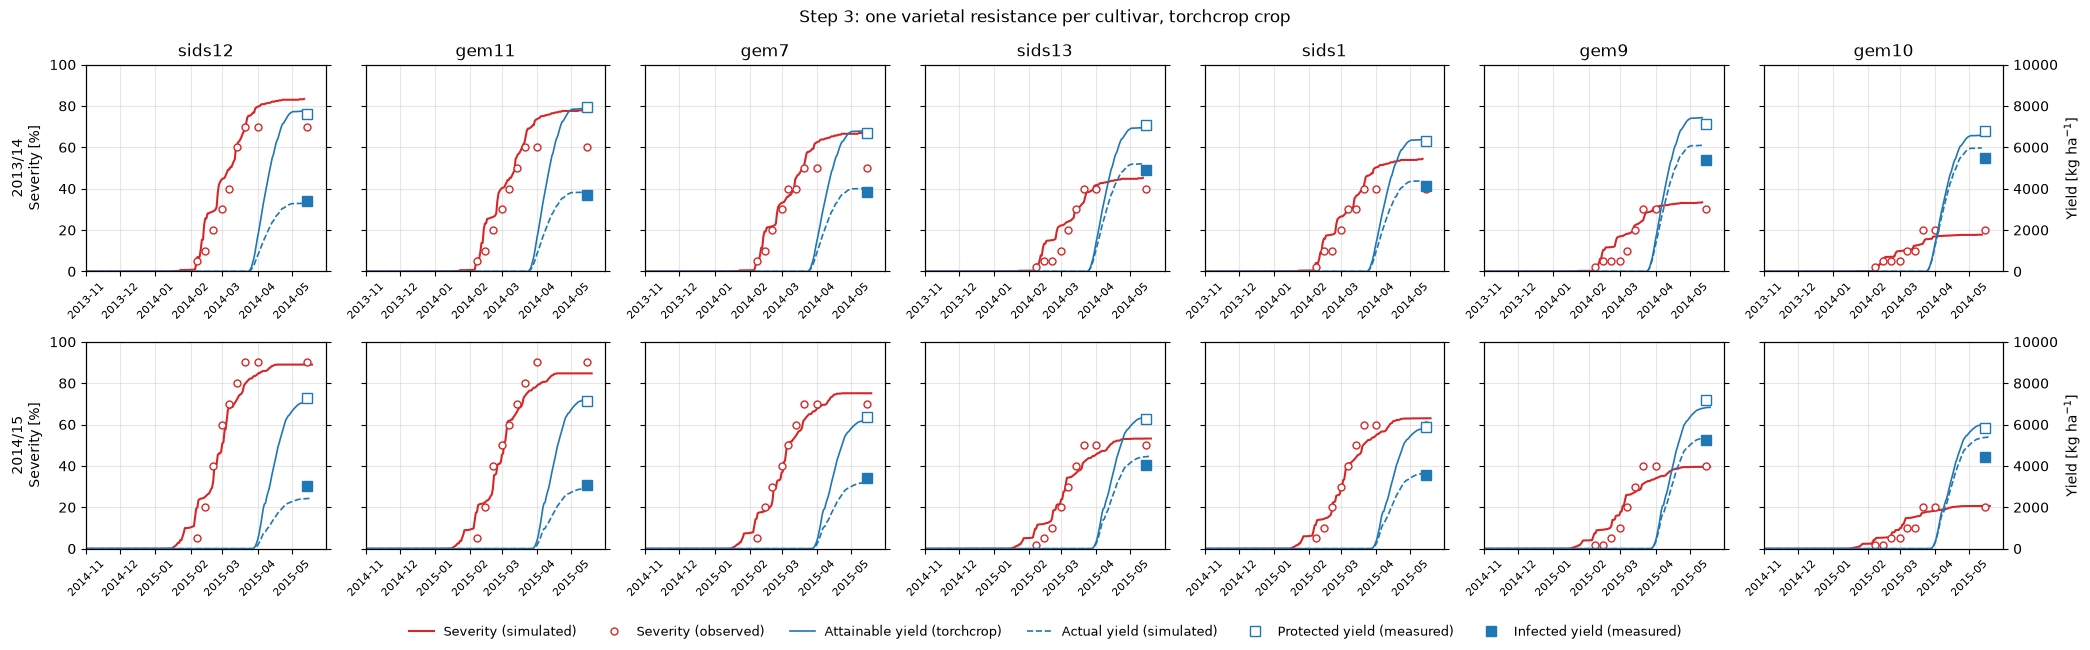

In [11]:
fig, axes = plt.subplots(2, len(VARIETIES), figsize=(3.0 * len(VARIETIES), 6.5), sharey=True)
for j, variety in enumerate(VARIETIES):
    sim = diag.simulation_frame(var_results[variety][1])
    for i, season in enumerate(SEASONS):
        ax2 = plot_variety(axes[i, j], sim, variety, season)
        if j < len(VARIETIES) - 1:
            ax2.set_yticklabels([])
        else:
            ax2.set_ylabel("Yield [kg ha$^{-1}$]")
    axes[0, j].set_title(variety)
for i, season in enumerate(SEASONS):
    axes[i, 0].set_ylabel(f"{season}/{season + 1 - 2000:02d}\nSeverity [%]")
handles = axes[0, 0].get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
fig.legend(handles, [h.get_label() for h in handles], loc="lower center", ncol=6, frameon=False, fontsize=9)
fig.suptitle("Step 3: one varietal resistance per cultivar, torchcrop crop")
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 8. Simulated vs measured yield loss

In [12]:
summary = pd.concat([
    fr.build_season_summary(diag.simulation_frame(res, severity_percent=False), "Sharkiya", v).assign(variety=v)
    for v, (cfg, res) in var_results.items()
])
loss = (summary.rename(columns={"GrowingSeason": "season"})
        [["variety", "season", "YieldAttainable", "YieldActual", "YieldLossPerc"]]
        .merge(yield_obs[["variety", "season", "yieldAttainable", "yieldActual", "loss_measured"]],
               on=["variety", "season"]))
loss["loss_error"] = loss["YieldLossPerc"] - loss["loss_measured"]

stats = loss.groupby("season").apply(lambda d: pd.Series({
    "RMSE loss [%-pt]": np.sqrt((d["loss_error"] ** 2).mean()),
    "bias [%-pt]": d["loss_error"].mean(),
    "r": np.corrcoef(d["YieldLossPerc"], d["loss_measured"])[0, 1],
}), include_groups=False)
display(stats.round(2))
loss.set_index(["variety", "season"]).loc[VARIETIES].round(1)

,RMSE loss [%-pt],bias [%-pt],r
season,,,
2013,5.19,-3.84,1.00
2014,6.61,-1.97,0.99


YieldAttainable  YieldActual  YieldLossPerc  yieldAttainable  \
variety season                                                                 
sids12  2013             7753.0       3292.1           57.5           7607.1   
        2014             7129.8       2428.4           65.9           7285.7   
gem11   2013             7872.5       3828.2           51.4           7964.3   
        2014             7241.4       2916.7           59.7           7142.9   
gem7    2013             6793.3       4008.1           41.0           6678.6   
        2014             6234.2       3207.2           48.6           6357.1   
sids13  2013             6950.0       5202.8           25.1           7071.4   
        2014             6380.2       4460.2           30.1           6250.0   
sids1   2013             6370.4       4377.4           31.3           6321.4   
        2014             5840.4       3654.3           37.4           5892.9   
gem9    2013             7432.1       6096.5           18.0           7107.1   
        2014             6830.0       5372.7           21.3           7178.6   
gem10   2013             6583.4       5971.6            9.3           6785.7   
        2014             6038.7       5391.1           10.7           5821.4   

                yieldActual  loss_measured  loss_error  
variety season                                          
sids12  2013         3392.9           55.4         2.1  
        2014         3035.7           58.3         7.6  
gem11   2013         3714.3           53.4        -2.0  
        2014         3071.4           57.0         2.7  
gem7    2013         3821.4           42.8        -1.8  
        2014         3392.9           46.6         1.9  
sids13  2013         4892.9           30.8        -5.7  
        2014         4035.7           35.4        -5.3  
sids1   2013         4107.1           35.0        -3.7  
        2014         3571.4           39.4        -2.0  
gem9    2013         5392.9           24.1        -6.1  
        2014         5250.0           26.9        -5.5  
gem10   2013         5500.0           18.9        -9.7  
        2014         4428.6           23.9       -13.2

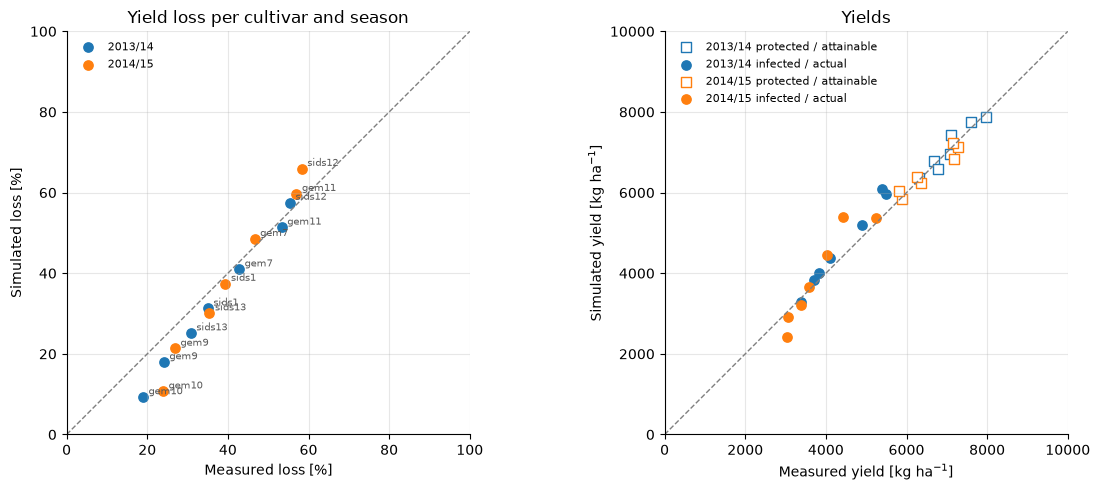

In [13]:
season_colors = {2013: "#1f77b4", 2014: "#ff7f0e"}
fig, (ax_l, ax_y) = plt.subplots(1, 2, figsize=(12, 5))
for season, d in loss.groupby("season"):
    label = f"{season}/{season + 1 - 2000:02d}"
    ax_l.scatter(d["loss_measured"], d["YieldLossPerc"], color=season_colors[season], s=45, label=label)
    for _, row in d.iterrows():
        ax_l.annotate(row["variety"], (row["loss_measured"], row["YieldLossPerc"]),
                      xytext=(4, 2), textcoords="offset points", fontsize=7, color="0.35")
    ax_y.scatter(d["yieldAttainable"], d["YieldAttainable"], color=season_colors[season], marker="s",
                 facecolors="white", s=45, label=f"{label} protected / attainable")
    ax_y.scatter(d["yieldActual"], d["YieldActual"], color=season_colors[season], s=45,
                 label=f"{label} infected / actual")
ax_l.plot([0, 100], [0, 100], color="0.5", lw=1, ls="--")
ax_l.set(xlim=(0, 100), ylim=(0, 100), xlabel="Measured loss [%]", ylabel="Simulated loss [%]",
         title="Yield loss per cultivar and season")
ax_y.plot([0, 10000], [0, 10000], color="0.5", lw=1, ls="--")
ax_y.set(xlim=(0, 10000), ylim=(0, 10000), xlabel="Measured yield [kg ha$^{-1}$]",
         ylabel="Simulated yield [kg ha$^{-1}$]", title="Yields")
for ax in (ax_l, ax_y):
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

In [14]:
sev_rmse = {}
for v, (cfg, res) in var_results.items():
    err = diag.match_ref_to_sim(diag.simulation_frame(res), ref_df[ref_df["variety"] == v],
                                SEASONS, "disease", "DiseaseSeverity")
    sev_rmse[v] = err.groupby("season")["error"].apply(lambda e: np.sqrt((e ** 2).mean()))
pd.DataFrame(sev_rmse).T.round(1).rename(columns=lambda s: f"severity RMSE {s}/{s + 1 - 2000:02d}")

season,severity RMSE 2013/14,severity RMSE 2014/15
sids12,9.5,8.1
gem11,8.4,7.6
gem7,6.1,5.5
sids13,6.9,5.5
sids1,6.0,5.1
gem9,6.3,6.1
gem10,3.3,3.4


## 9. Summary and limits

**Crop (torchcrop).** Maturity on DOY 135 needs `TSUM1` = 2625 °C d (preset
1050), which puts anthesis on 30 March 2014 and 3 April 2015 and maturity on
12 and 19 May. One `scale_factor_rue` per cultivar (0.77–0.95) brings the
potential yield within 178 kg ha⁻¹ (RMSE) of the fourteen protected-plot
yields. With one value for both seasons, the weather alone makes 2014/15 the
lower-yielding season for every cultivar; the measured protected yield was
lower in 2014/15 for six of the seven.

**Disease (step 2).** Objective 9.10 on Sids-12. `LightStealerDamage` ends on
its lower bound (0.52, bound 0.5), and so does `RelativeHumidityCritical`.

**Cultivars (step 3).** `VarietalResistance` runs from Sids-12 (0.05) to
Gem-10 (0.78), in the paper's order of final severity and AUDPC. Severity
RMSE is 3.3–9.5 points per cultivar-season.

**Yield loss (section 8).**

| | 2013/14 | 2014/15 |
|---|---|---|
| RMSE [points] | 5.2 | 6.6 |
| bias [points] | −3.8 | −2.0 |
| same, notebook 1 (internal crop) | 4.8, +0.3 | 11.0, +6.2 |

- The overestimate of the susceptible cultivars in 2014/15 is smaller than
  with the internal crop (Sids-12 66 against 58 %, notebook 1: 76 %).
- The resistant cultivars are underestimated in both seasons: Gem-10 9 and
  11 % against 19 and 24 %, Gem-9 18 and 21 % against 24 and 27 %, Sids-13
  25 and 30 % against 31 and 35 %.

Measured loss relative to severity is higher on the resistant cultivars
(Gem-10: 19–24 % loss at 20 % final severity) than on the susceptible ones
(Sids-12: 55–58 % loss at 70–90 %). With the light stealer as the only
damage mechanism, at its lowest allowed coefficient, the model cannot
reproduce both.

**Limits.** Those of notebook 1 (loss fitted, not predicted; assumed sowing
and harvest dates; placeholder `fint`; gridded weather; two seasons at one
site), plus:

1. Phenology is set from an assumed maturity date with the preset
   grain-filling thermal time, not calibrated against observed dates.
2. Potential production assumes no water or nitrogen limitation; the trial's
   irrigation and fertilisation are not reported.
3. All cultivars share the preset Lintul5 parameters except
   `scale_factor_rue`; real differences in phenology or partitioning between
   cultivars are absorbed by it.
4. torchcrop's yield is dry matter, the measured yields are at market
   moisture.